# Full reaction network -> carbon-only subgraph -> pathway, one location

What: three visualisations (full reaction network, carbon-containing-
species-only subgraph, pathway), built directly from stage 03's
converted output and stage 04's saved rates. `conversion` (below)
picks CH4-to-CO or CO-to-CH4, same as
`calc_paths_serial()` - `build_unidirect_graph()` for CH4-to-CO,
`build_bidirect_graph()` for CO-to-CH4 (see either's own docstring for
why). A useful way to interactively test/inspect quenchpath's core
per-location graph stages
(`quenchpath.stages.stage_05_paths_serial.load_eqns_with_rates`,
`quenchpath.graph.shortest_path.build_unidirect_graph`/
`build_bidirect_graph`/`prune_to_carbon_subgraph`/`find_pathway`) with
a plot at every step.

Why built this way: works directly from stage 03's converted output
and stage 04's saved rates rather than depending on a completed
`calc-paths-serial`/`calc-paths-parallel` run for this location.

What: `use_bundled_example` (default True) runs this notebook out of
the box against a small pre-extracted `example_data/` snapshot (one
hd189733b location's own 180 reactions' k_eq/rate_f/rate_r plus every
gas's number density there, ~30KB total), and `pres`/`lat`/`lon` below
are ignored (the snapshot is one frozen point). Set it to False to pick
any location from a real completed `convert`/`calc-rates` run instead -
see the prerequisites below.

Why: no completed pipeline run is needed to try the notebook this way.

What: supersedes the original plt_network.ipynb (moved to a separate
sibling repo for freezing); this notebook reproduces its
*computations* with a simpler, self-contained networkx+matplotlib
approach instead.

Why superseded: plt_network.ipynb used a different, pyvista/graphviz-
adjacent drawing style and an import never migrated into this repo.

In [1]:
import json
import warnings

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import yaml

from quenchpath import io
from quenchpath.chemistry.network import VENOT2019
from quenchpath.config import RunConfig, SpeciesConversion
from quenchpath.graph.shortest_path import (
    EQNS_W_FOUR_C,
    build_bidirect_graph,
    build_unidirect_graph,
    find_pathway,
    prune_to_carbon_subgraph,
)
from quenchpath.mypaths import (
    path_to_data_root,
    path_to_example_data,
    path_to_planets_yaml,
    path_to_plots,
)
from quenchpath.stages.stage_04_rates import split_gases_and_bath_gases
from quenchpath.stages.stage_05_paths_serial import load_eqns_with_rates

warnings.filterwarnings("ignore", module="iris")

# What: title uses inputs/run_metadata/planets.yaml's own display-name
# convention (e.g. "HAT-P-11b") verbatim, not $-wrapped.
# Why: mathtext renders a bare "-" as a spaced minus sign - see
# notebooks/plt_slices.ipynb's own PLANET_NAMES comment for the fuller
# explanation.
with open(path_to_planets_yaml) as f:
    PLANET_NAMES = {k: v["tex"] for k, v in yaml.safe_load(f).items()}

## Choose a location and load its reactions/rates/gas number densities

In [2]:
use_bundled_example = True  # see this notebook's own markdown intro above

planet = "hd189733b"
exp = "kin"
mdh = "0"
tK = "1"
pres, lat, lon = 1e5, -19.0, 1.25  # nearest native grid point is used
# (ignored when use_bundled_example=True - see the markdown intro)
conversion = SpeciesConversion.CH4_CO  # or SpeciesConversion.CO_CH4

In [3]:
cfg = RunConfig(planet=planet, exp=exp, mdh=mdh, tK=tK)

if use_bundled_example:
    snapshot_path = path_to_example_data / f"{planet}_{exp}_mdh{mdh}_tK{tK}_location_snapshot.json"
    with open(snapshot_path) as f:
        snapshot = json.load(f)
    eqns_at_location = snapshot["eqns_at_location"]
    number_density = snapshot["number_density"]
    resolved_lat, resolved_lon, resolved_pres = (
        snapshot["lat"],
        snapshot["lon"],
        snapshot["pres"],
    )
    temp = snapshot["temp"]
    print(
        f"Bundled example location: pres={resolved_pres:.1e}, lat={resolved_lat}, "
        f"lon={resolved_lon}, temp={temp:.0f} K"
    )
else:
    eqns = load_eqns_with_rates(cfg)
    converted_cubes = io.load_converted(cfg)

    temp_cube = converted_cubes.extract_cube("air_temperature")
    pres_cube = converted_cubes.extract_cube("air_pressure")
    full_lats = temp_cube.coord("latitude").points
    full_lons = temp_cube.coord("longitude").points
    lai = int(np.argmin(np.abs(full_lats - lat)))
    loi = int(np.argmin(np.abs(full_lons - lon)))
    # What: nearest level to `pres` is looked up in this specific
    # column's own real pressure profile, not off a global coordinate.
    # Why: pressure isn't a shared axis across columns any more (see
    # quenchpath-apps issue #11).
    pres_profile = pres_cube.data[:, lai, loi]
    pi = int(np.argmin(np.abs(pres_profile - pres)))
    resolved_lat, resolved_lon, resolved_pres = full_lats[lai], full_lons[loi], pres_profile[pi]
    temp = float(temp_cube.data[pi, lai, loi])
    print(
        f"Nearest grid point to (pres={pres:.1e}, lat={lat}, lon={lon}): "
        f"pres={resolved_pres:.1e}, lat={resolved_lat}, lon={resolved_lon}, temp={temp:.0f} K"
    )

    # What: index every reaction's k_eq/rate_f/rate_r at this one
    # location.
    # Why: same construction
    # quenchpath.stages.stage_05_paths_serial.calc_paths_serial() uses
    # internally.
    eqns_at_location = [
        {
            "eqn": eqn["eqn"],
            "reacs": eqn["reacs"],
            "prods": eqn["prods"],
            "k_eq": float(eqn["k_eq"].data[pi, lai, loi]),
            "rate_f": float(eqn["rate_f"].data[pi, lai, loi]),
            "rate_r": float(eqn["rate_r"].data[pi, lai, loi]),
        }
        for eqn in eqns
    ]
    # What: every gas's number density at this location, from stage
    # 03's converted output.
    # Why: same convention as notebooks/plt_network.ipynb's
    # node_sizes.
    all_gases, _ = split_gases_and_bath_gases(converted_cubes, VENOT2019["bath_gases"])
    number_density = {gas.name(): float(gas.data[pi, lai, loi]) for gas in all_gases}

Bundled example location: pres=9.3e+04, lat=-19.0, lon=1.25, temp=1401 K


In [4]:
# Node sizes: log10(number density) at this location, for every gas
# `number_density` (cell above) has an entry for.
def node_size(species):
    nd = number_density.get(species)
    return abs(np.log10(nd)) * 130 if nd else 300

In [5]:
def plot_reaction_graph(G, title="", show_edge_labels=True, ax=None):
    """What: draw a reaction (sub)graph - one node per species (sized
    by log10(number density) at this location, where known), one edge
    per reaction (color = log10(1/rate) - darker/higher = slower, a
    bottleneck step), edge labels = the reaction equation string (only
    if `show_edge_labels`). Works for any of the three graphs below
    (full network, carbon subgraph, CH4-to-CO pathway) - all share the
    same eqn/seg_rate_inv edge attribute schema, set by
    quenchpath.graph.shortest_path; edge_color (log10(1/rate)) is
    computed here at plot time, not persisted.

    Why `show_edge_labels` is optional: the full network/carbon
    subgraph below have too many edges for labels to stay readable.
    """
    if ax is None:
        _, ax = plt.subplots(figsize=(11, 11))
    pos = nx.spring_layout(G, seed=0, k=0.6)
    sizes = [node_size(n) for n in G.nodes()]
    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=sizes, node_color="sandybrown")
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=9)
    edge_colors = [np.log10(d["seg_rate_inv"]) for _, _, d in G.edges(data=True)]
    nx.draw_networkx_edges(
        G,
        pos,
        ax=ax,
        edge_color=edge_colors,
        edge_cmap=plt.cm.viridis_r,
        width=1.2,
        arrows=True,
        arrowstyle="-|>",
        node_size=sizes,
    )
    if show_edge_labels:
        edge_labels = {(u, v): d["eqn"] for u, v, d in G.edges(data=True)}
        nx.draw_networkx_edge_labels(G, pos, ax=ax, edge_labels=edge_labels, font_size=7)
    ax.axis("off")
    ax.set_title(title, loc="left")
    if edge_colors:
        plt.colorbar(
            plt.cm.ScalarMappable(
                norm=plt.Normalize(vmin=min(edge_colors), vmax=max(edge_colors)),
                cmap=plt.cm.viridis_r,
            ),
            ax=ax,
            label=r"$\log_{10}$(1 / rate) - lighter = faster step",
            shrink=0.6,
        )
    return ax


def save_figure(fig, figname):
    # What: figname may itself name a subdirectory (e.g.
    # "graphs/graph_...") - create that, not just path_to_plots.
    # Why: matches quenchpath.viz.save_figure()'s own behavior.
    out_path = path_to_plots / f"{figname}.png"
    out_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(out_path, bbox_inches="tight", dpi=150)
    print(f"Saved {out_path.relative_to(path_to_data_root)}")


title_prefix = (
    f"{PLANET_NAMES.get(planet, planet)} ({exp})  {resolved_lat:.0f} lat, "
    f"{resolved_lon:.0f} lon, {resolved_pres:.1e} Pa, {temp:.0f} K - {conversion.label}"
)
# What: location (lat/lon/pres/exp) shows in the plot title
# (title_prefix above) but not the saved filename.
# Why: keeps one canonical graph_* file set per (planet, conversion) -
# re-running for a different location overwrites those same 3 files
# rather than accumulating one set per location.
figname_prefix = (
    f"graphs/graph_{planet}_{conversion.source.lower()}_{conversion.target.lower()}"
)

# What: which graph-construction function this search uses.
# Why: see calc_paths_serial()'s own docstring
# (quenchpath.stages.stage_05_paths_serial) - CH4_CO/CO_CH4 need
# different ones.
build_graph = (
    build_bidirect_graph if conversion == SpeciesConversion.CO_CH4 else build_unidirect_graph
)

## Full reaction network

Saved outputs/results/plots/graphs/graph_hd189733b_ch4_co_full.png


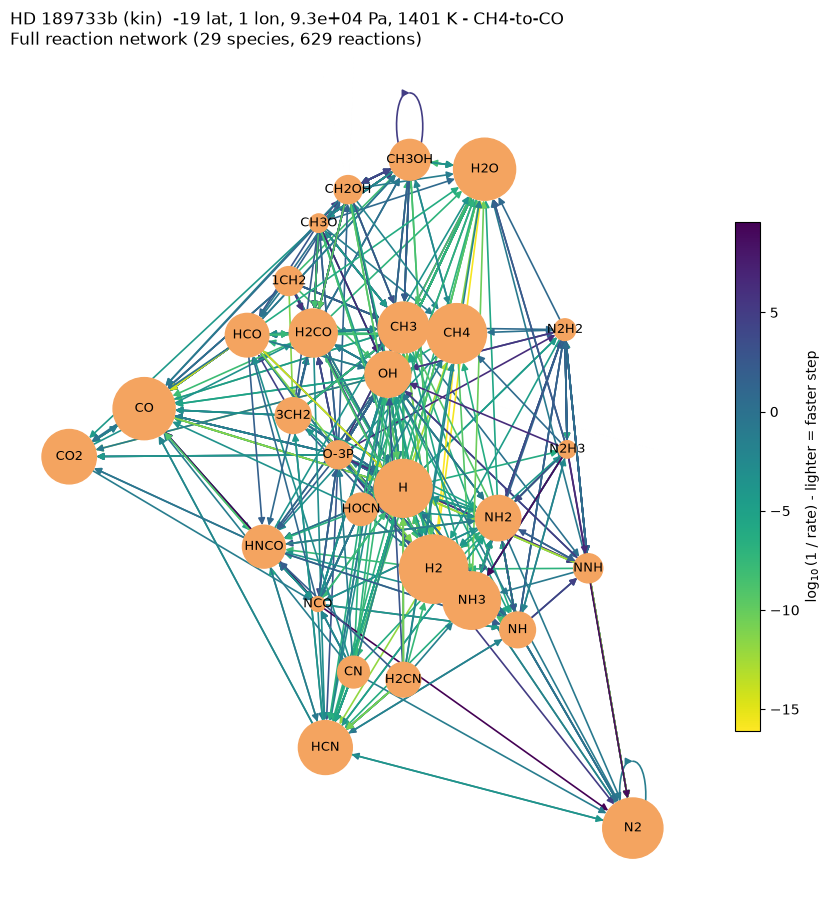

In [6]:
G = build_graph(eqns_at_location)
title = (
    f"{title_prefix}\nFull reaction network ({G.number_of_nodes()} species, "
    f"{G.number_of_edges()} reactions)"
)
ax = plot_reaction_graph(G, title=title, show_edge_labels=False)
save_figure(ax.figure, f"{figname_prefix}_full")

## Carbon-containing subgraph

Saved outputs/results/plots/graphs/graph_hd189733b_ch4_co_carbon.png


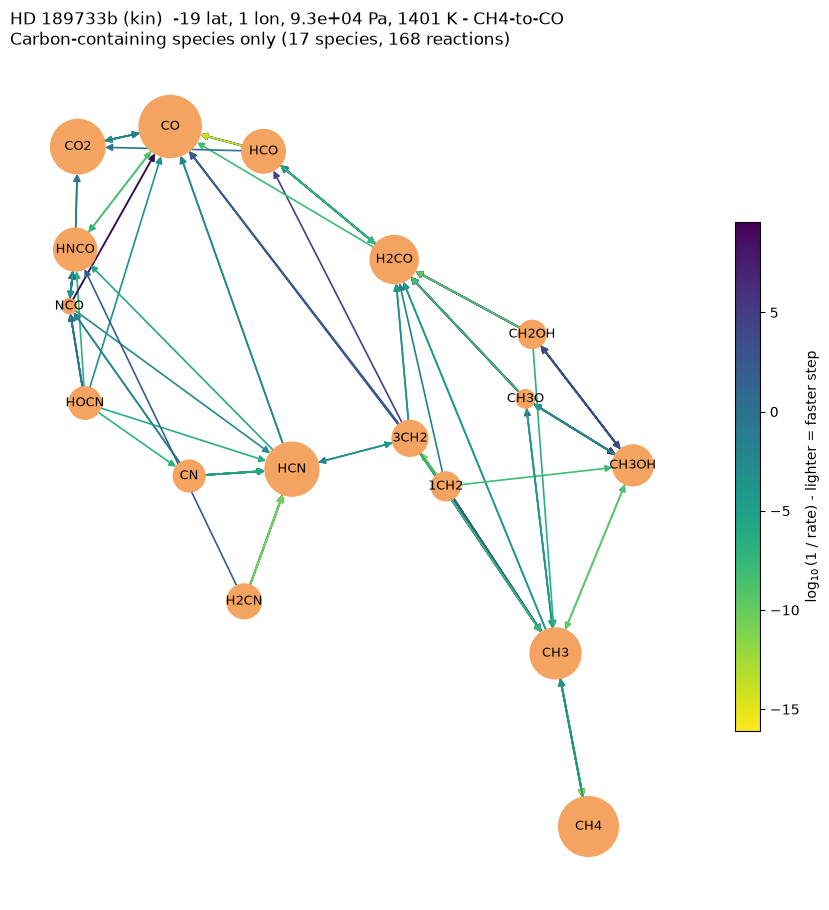

In [7]:
SG_tidy = prune_to_carbon_subgraph(G, EQNS_W_FOUR_C)
ax = plot_reaction_graph(
    SG_tidy,
    title=(
        f"{title_prefix}\nCarbon-containing species only "
        f"({SG_tidy.number_of_nodes()} species, {SG_tidy.number_of_edges()} reactions)"
    ),
    show_edge_labels=False,
)
save_figure(ax.figure, f"{figname_prefix}_carbon")

## CH4-to-CO pathway

Saved outputs/results/plots/graphs/graph_hd189733b_ch4_co_shortest.png
Pathway: CH4+H↔CH3+H2 | OH+CH3(+M)↔CH3OH(+M) | CH2OH+H2↔CH3OH+H | CH2OH+M↔H2CO+H+M | H2CO+H↔HCO+H2 | HCO+M↔H+CO+M
net_rate_inv: 2.488e-08 cm3 s, max_rate_inv: 2.174e-08 cm3 s


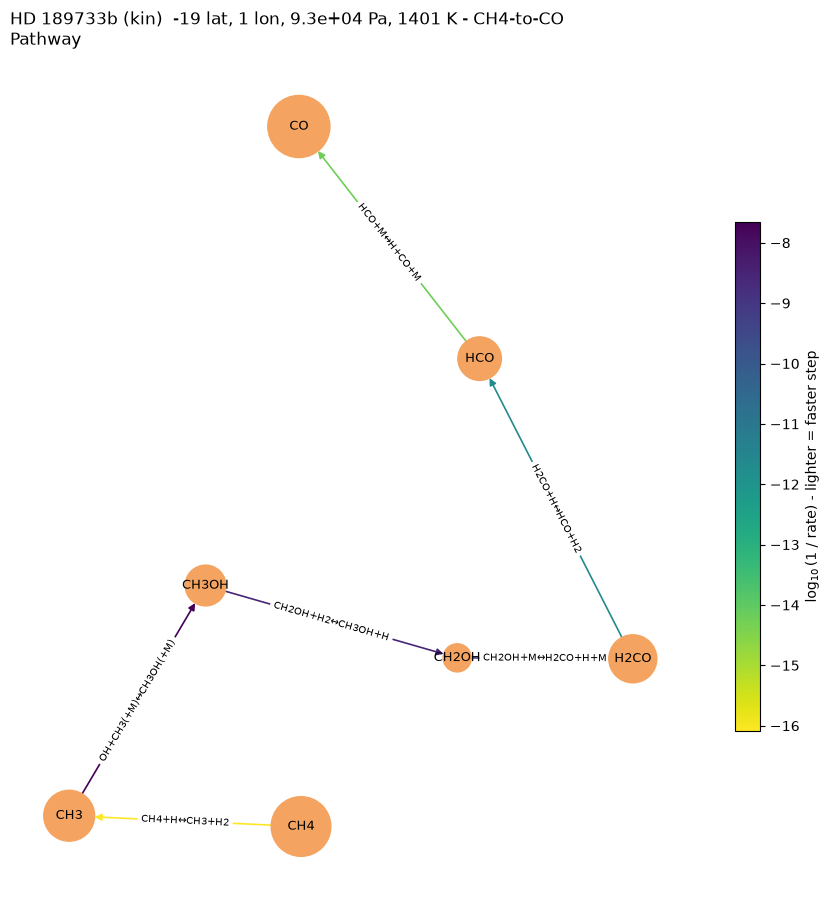

In [8]:
net_rate_inv, max_rate_inv, nodes, segments = find_pathway(
    SG_tidy, source=conversion.source, target=conversion.target
)
SP = nx.DiGraph()
for (species_from, species_to), segment in zip(zip(nodes, nodes[1:]), segments):
    SP.add_edge(
        species_from, species_to, eqn=segment["eqn"], seg_rate_inv=segment["seg_rate_inv"]
    )

ax = plot_reaction_graph(SP, title=f"{title_prefix}\nPathway", show_edge_labels=True)
save_figure(ax.figure, f"{figname_prefix}_shortest")
print("Pathway:", " | ".join(segment["eqn"] for segment in segments))
print(f"net_rate_inv: {net_rate_inv:.3e} cm3 s, max_rate_inv: {max_rate_inv:.3e} cm3 s")